# ENGE707 Kaggle Competition: Geometry and Preprocessing Robustness Audit

## Controlled Inference Experiment

The original ResNet18 achieved **99.65%** validation accuracy but **94.63%** on the Kaggle leaderboard. A group-aware retraining experiment still achieved **99.62%**, which showed that detected near-duplicate leakage did not explain the gap.

Dataset exploration found a stronger difference in image geometry: approximately **65.5%** of labelled images are square, compared with **32.9%** of Kaggle test images. This notebook therefore tests whether padding and resizing choices affect model generalisation.

The notebook:

1. loads the group-aware ResNet18 checkpoint;
2. evaluates five deterministic preprocessing views on the same group-aware validation images;
3. evaluates low-cost ensembles without changing any model weights;
4. reports overall, non-square, high-padding, per-class, and geometry-bin accuracy;
5. uses paired tests to separate clear evidence from small random changes; and
6. saves tables and figures for the report.

**No training is performed and no Kaggle test image is loaded.**

## 1. Import the Required Libraries

PyTorch performs inference, SciPy provides an exact paired comparison, and Matplotlib creates report evidence.

In [7]:
# Imports the libraries used to compare image preprocessing methods
from pathlib import Path
from contextlib import nullcontext
from zipfile import ZipFile, ZIP_DEFLATED
import hashlib
import io
import json
import random
import shutil
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.transforms import InterpolationMode

from scipy.stats import binomtest
from sklearn.metrics import accuracy_score, f1_score

from IPython.display import FileLink, Markdown, display

## 2. Locate the Saved Inputs

The notebook accepts either direct files or the result ZIP created by Notebook 9. Ambiguous matches cause an error rather than silently loading the wrong checkpoint.

In [8]:
# Finds the group aware checkpoint validation split and required settings
RUNNING_ON_KAGGLE = Path("/kaggle/input").exists()


def find_kaggle_file(filename, required=True, preferred_text=None):
    """Return one unambiguous matching Kaggle input file."""
    matches = sorted(Path("/kaggle/input").rglob(filename))
    if preferred_text:
        preferred = [
            path for path in matches
            if preferred_text.lower() in str(path).lower()
        ]
        if preferred:
            matches = preferred

    if len(matches) == 1:
        return matches[0]
    if not required and len(matches) == 0:
        return None

    match_text = "\n".join(str(path) for path in matches)
    raise RuntimeError(
        f"Expected exactly one {filename}, found {len(matches)}.\n"
        f"Matches:\n{match_text}"
    )


def find_image_directory(filename, split_name):
    """Find one image folder containing a known split file."""
    matches = sorted(Path("/kaggle/input").rglob(filename))
    matches = [
        path for path in matches
        if split_name.lower() in {
            part.lower() for part in path.parent.parts
        }
    ]
    directories = sorted({path.parent for path in matches})
    if len(directories) != 1:
        directory_text = "\n".join(str(path) for path in directories)
        raise RuntimeError(
            f"Expected one {split_name} image directory, found "
            f"{len(directories)}.\n{directory_text}"
        )
    return directories[0]


def extract_named_member(archive_path, filename, destination):
    """Extract one uniquely named member from a result archive."""
    with ZipFile(archive_path) as archive:
        matches = [
            name for name in archive.namelist()
            if Path(name).name == filename
        ]
        if len(matches) != 1:
            raise RuntimeError(
                f"Expected one {filename} in {archive_path}, "
                f"found {len(matches)}."
            )
        destination.parent.mkdir(parents=True, exist_ok=True)
        with archive.open(matches[0]) as source:
            with open(destination, "wb") as target:
                shutil.copyfileobj(source, target)
    return destination


if RUNNING_ON_KAGGLE:
    PROJECT_ROOT = Path("/kaggle/working")

    VALIDATION_SPLIT_PATH = find_kaggle_file(
        "validation_split_group_aware.csv",
        required=False,
    )
    if VALIDATION_SPLIT_PATH is None:
        split_archive = find_kaggle_file(
            "group_aware_split_results.zip"
        )
        VALIDATION_SPLIT_PATH = extract_named_member(
            split_archive,
            "validation_split_group_aware.csv",
            PROJECT_ROOT / "validation_split_group_aware.csv",
        )

    PREPROCESSING_CONFIG_PATH = find_kaggle_file(
        "preprocessing_config.json",
        preferred_text="facial-feature-project-artifacts",
    )

    CHECKPOINT_PATH = find_kaggle_file(
        "resnet18_group_aware_best.pth",
        required=False,
    )
    if CHECKPOINT_PATH is None:
        result_archive = find_kaggle_file(
            "group_aware_resnet18_baseline_results.zip"
        )
        CHECKPOINT_PATH = extract_named_member(
            result_archive,
            "resnet18_group_aware_best.pth",
            PROJECT_ROOT / "resnet18_group_aware_best.pth",
        )

    validation_probe = pd.read_csv(
        VALIDATION_SPLIT_PATH,
        dtype={"filename": "string"},
        nrows=1,
    ).iloc[0]["filename"]
    TRAIN_IMAGE_DIR = find_image_directory(
        validation_probe,
        "train",
    )
else:
    possible_roots = [Path.cwd(), Path.cwd().parent]
    PROJECT_ROOT = next(
        (
            folder for folder in possible_roots
            if (
                folder
                / "splits"
                / "group_aware"
                / "validation_split_group_aware.csv"
            ).exists()
        ),
        None,
    )
    if PROJECT_ROOT is None:
        raise FileNotFoundError("The project root could not be located.")

    VALIDATION_SPLIT_PATH = (
        PROJECT_ROOT
        / "splits"
        / "group_aware"
        / "validation_split_group_aware.csv"
    )
    PREPROCESSING_CONFIG_PATH = (
        PROJECT_ROOT
        / "outputs"
        / "preprocessing"
        / "preprocessing_config.json"
    )
    CHECKPOINT_PATH = (
        PROJECT_ROOT
        / "models"
        / "group_aware_baseline"
        / "resnet18_group_aware_best.pth"
    )
    TRAIN_IMAGE_DIR = PROJECT_ROOT / "data" / "train" / "train"

EXPERIMENT_DIR = (
    PROJECT_ROOT / "outputs" / "improvements" / "geometry_robustness"
)
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

required_paths = [
    VALIDATION_SPLIT_PATH,
    PREPROCESSING_CONFIG_PATH,
    CHECKPOINT_PATH,
    TRAIN_IMAGE_DIR,
]
missing_paths = [path for path in required_paths if not path.exists()]
if missing_paths:
    raise FileNotFoundError(
        "Missing required inputs:\n"
        + "\n".join(str(path) for path in missing_paths)
    )

print("Environment:", "Kaggle" if RUNNING_ON_KAGGLE else "Local")
print("Validation split:", VALIDATION_SPLIT_PATH)
print("Checkpoint:", CHECKPOINT_PATH)
print("Training images:", TRAIN_IMAGE_DIR)

Environment: Kaggle
Validation split: /kaggle/input/datasets/fatehbhular/facial-feature-group-split-training/validation_split_group_aware.csv
Checkpoint: /kaggle/input/datasets/fatehbhular/resnet18-group-aware-best-pth/resnet18_group_aware_best.pth
Training images: /kaggle/input/datasets/fatehbhular/ense707-facial-feature-competition-data/train/train


## 3. Load and Verify the Configuration

The saved class order and normalization values are reused exactly. The group-aware validation set remains untouched.

In [9]:
# Checks the saved class mapping and validation configuration
with open(PREPROCESSING_CONFIG_PATH) as config_file:
    preprocessing_config = json.load(config_file)

validation_split = pd.read_csv(
    VALIDATION_SPLIT_PATH,
    dtype={
        "image_id": "string",
        "class": "string",
        "filename": "string",
        "group_id": "string",
    },
)

IMAGE_SIZE = int(preprocessing_config["image_size"])
CLASS_NAMES = list(preprocessing_config["class_names"])
CLASS_TO_INDEX = dict(preprocessing_config["class_to_index"])
INDEX_TO_CLASS = {
    int(index): class_name
    for class_name, index in CLASS_TO_INDEX.items()
}
IMAGENET_MEAN = list(preprocessing_config["normalisation_mean"])
IMAGENET_STD = list(preprocessing_config["normalisation_std"])
NUMBER_OF_CLASSES = len(CLASS_NAMES)

expected_indices = validation_split["class"].map(CLASS_TO_INDEX)
if expected_indices.isna().any():
    raise ValueError("The validation split contains an unknown class.")

if "label_index" in validation_split.columns:
    mapping_matches = (
        validation_split["label_index"].astype(int)
        == expected_indices.astype(int)
    ).all()
    if not mapping_matches:
        raise ValueError("Saved label indices do not match the official mapping.")

validation_split["label_index"] = expected_indices.astype(int)

print("Validation images:", f"{len(validation_split):,}")
print("Classes:", CLASS_NAMES)
print("Image size:", IMAGE_SIZE)
print("Class mapping verified:", True)

Validation images: 12,732
Classes: ['CatEye', 'DogEye', 'CatFace', 'DogFace', 'CatMouth', 'DogMouth', 'CatNose', 'DogNose']
Image size: 224
Class mapping verified: True


## 4. Configure Reproducible Inference

No randomness is used in any evaluated transform. Two GPUs are used when available, but prediction order remains identical to the validation CSV.

In [10]:
# Sets repeatable inference options and the evaluation batch size
RANDOM_SEED = 42
BATCH_SIZE = 256 if torch.cuda.is_available() else 32
NUM_WORKERS = 2 if RUNNING_ON_KAGGLE else 0
PIN_MEMORY = torch.cuda.is_available()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_MIXED_PRECISION = DEVICE.type == "cuda"

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

print("Device:", DEVICE)
print("CUDA devices:", torch.cuda.device_count())
print("Batch size:", BATCH_SIZE)
print("Mixed precision:", USE_MIXED_PRECISION)

Device: cuda
CUDA devices: 2
Batch size: 256
Mixed precision: True


## 5. Define the Controlled Preprocessing Views

The baseline exactly reproduces training-time validation preprocessing. The alternatives change only how the original aspect ratio is handled:

- **Black square padding:** the existing baseline.
- **Reflection padding:** fills empty space with mirrored image content.
- **ImageNet-mean padding:** creates approximately zero-valued normalized borders.
- **Direct resize:** removes padding but stretches the image.
- **Resize and centre crop:** preserves aspect ratio but removes outer image regions.

These are deterministic inference experiments, not new training pipelines.

In [11]:
# Defines the fixed padding resizing and cropping views being compared
class SquarePad:
    """Pad an RGB image to a square with one fixed colour."""

    def __init__(self, fill=(0, 0, 0)):
        self.fill = fill

    def __call__(self, image):
        width, height = image.size
        side = max(width, height)
        horizontal = side - width
        vertical = side - height
        left = horizontal // 2
        right = horizontal - left
        top = vertical // 2
        bottom = vertical - top
        return ImageOps.expand(
            image,
            border=(left, top, right, bottom),
            fill=self.fill,
        )


class ReflectSquarePad:
    """Pad to a square by reflecting edge content."""

    def __call__(self, image):
        image_array = np.asarray(image)
        height, width = image_array.shape[:2]
        side = max(width, height)
        horizontal = side - width
        vertical = side - height
        left = horizontal // 2
        right = horizontal - left
        top = vertical // 2
        bottom = vertical - top
        padded = np.pad(
            image_array,
            ((top, bottom), (left, right), (0, 0)),
            mode="reflect",
        )
        return Image.fromarray(padded)


normalise = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
to_model_tensor = [transforms.ToTensor(), normalise]
mean_fill = tuple(round(value * 255) for value in IMAGENET_MEAN)

evaluation_transforms = {
    "baseline_black_pad": transforms.Compose(
        [
            SquarePad(fill=(0, 0, 0)),
            transforms.Resize(
                (IMAGE_SIZE, IMAGE_SIZE),
                interpolation=InterpolationMode.BILINEAR,
            ),
            *to_model_tensor,
        ]
    ),
    "reflect_pad": transforms.Compose(
        [
            ReflectSquarePad(),
            transforms.Resize(
                (IMAGE_SIZE, IMAGE_SIZE),
                interpolation=InterpolationMode.BILINEAR,
            ),
            *to_model_tensor,
        ]
    ),
    "imagenet_mean_pad": transforms.Compose(
        [
            SquarePad(fill=mean_fill),
            transforms.Resize(
                (IMAGE_SIZE, IMAGE_SIZE),
                interpolation=InterpolationMode.BILINEAR,
            ),
            *to_model_tensor,
        ]
    ),
    "direct_resize": transforms.Compose(
        [
            transforms.Resize(
                (IMAGE_SIZE, IMAGE_SIZE),
                interpolation=InterpolationMode.BILINEAR,
            ),
            *to_model_tensor,
        ]
    ),
    "resize_center_crop": transforms.Compose(
        [
            transforms.Resize(
                256,
                interpolation=InterpolationMode.BILINEAR,
            ),
            transforms.CenterCrop(IMAGE_SIZE),
            *to_model_tensor,
        ]
    ),
}

for method_name, method_transform in evaluation_transforms.items():
    assert "Random" not in repr(method_transform)
    print(f"\n{method_name}:\n{method_transform}")


baseline_black_pad:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

reflect_pad:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

imagenet_mean_pad:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

direct_resize:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

resize_center_crop:
Compose(
    Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.2

## 6. Build an Order-Preserving Validation Loader

Every method uses the same rows and labels. Original width and height are retained for geometry subgroup analysis.

In [12]:
# Loads validation images while keeping their original size information
class GeometryValidationDataset(Dataset):
    """Load validation images and retain their original geometry."""

    def __init__(self, dataframe, image_directory, transform):
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.image_directory = Path(image_directory)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image_path = self.image_directory / row["filename"]
        with Image.open(image_path) as image:
            image = image.convert("RGB")
            width, height = image.size
            transformed_image = self.transform(image)

        return {
            "image": transformed_image,
            "image_id": str(row["image_id"]),
            "filename": str(row["filename"]),
            "label": int(row["label_index"]),
            "width": width,
            "height": height,
        }


def build_validation_loader(method_transform):
    dataset = GeometryValidationDataset(
        validation_split,
        TRAIN_IMAGE_DIR,
        method_transform,
    )
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
        persistent_workers=False,
    )


example_loader = build_validation_loader(
    evaluation_transforms["baseline_black_pad"]
)
print("Validation batches per view:", len(example_loader))
print("Validation images:", len(example_loader.dataset))

Validation batches per view: 50
Validation images: 12732


## 7. Load and Freeze the Group-Aware ResNet18

The selected epoch-9 checkpoint is loaded without pretrained downloads. All parameters are frozen and the model is placed in evaluation mode.

In [13]:
# Loads the group aware ResNet18 and disables weight updates
# Reads the saved checkpoint so training does not need to be repeated
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

checkpoint_classes = list(checkpoint.get("class_names", []))
if checkpoint_classes != CLASS_NAMES:
    raise ValueError(
        "Checkpoint class order does not match preprocessing configuration."
    )
if int(checkpoint.get("image_size", -1)) != IMAGE_SIZE:
    raise ValueError("Checkpoint image size does not match the configuration.")

base_model = models.resnet18(weights=None)
base_model.fc = nn.Linear(
    base_model.fc.in_features,
    NUMBER_OF_CLASSES,
)
state_dict = {
    key.removeprefix("module."): value
    for key, value in checkpoint["model_state_dict"].items()
}
# Copies the saved weights into the matching model architecture
base_model.load_state_dict(state_dict)

for parameter in base_model.parameters():
    parameter.requires_grad = False

initial_parameters = {
    name: parameter.detach().cpu().clone()
    for name, parameter in base_model.named_parameters()
}

base_model = base_model.to(DEVICE)
if DEVICE.type == "cuda":
    base_model = base_model.to(memory_format=torch.channels_last)

model = base_model
if DEVICE.type == "cuda" and torch.cuda.device_count() > 1:
    model = nn.DataParallel(model)

# Switches the model to evaluation behaviour for prediction
model.eval()

print("Checkpoint epoch:", checkpoint.get("epoch"))
print(
    "Saved group-aware validation accuracy:",
    f"{checkpoint.get('validation_accuracy', float('nan')):.4%}",
)
print("Parameters trainable:", sum(p.requires_grad for p in model.parameters()))
print("DataParallel enabled:", isinstance(model, nn.DataParallel))

Checkpoint epoch: 9
Saved group-aware validation accuracy: 99.6230%
Parameters trainable: 0
DataParallel enabled: True


## 8. Evaluate Every Deterministic View

Logits are retained so ensembles can be created without reading images or running the model again. A horizontal-flip view is generated during the baseline pass.

In [14]:
# Evaluates the same model using each fixed preprocessing view
def mixed_precision_context():
    if USE_MIXED_PRECISION:
        return torch.autocast(device_type="cuda", dtype=torch.float16)
    return nullcontext()


def run_view_inference(method_name, method_transform, include_flip=False):
    loader = build_validation_loader(method_transform)
    logits_batches = []
    flipped_logits_batches = []
    labels_batches = []
    image_ids = []
    filenames = []
    widths = []
    heights = []

    # Switches the model to evaluation behaviour for prediction
    model.eval()
    start_time = time.perf_counter()
    # Disables gradient tracking because this step does not train the model
    with torch.inference_mode():
        for batch in loader:
            images = batch["image"].to(
                DEVICE,
                non_blocking=PIN_MEMORY,
            )
            if DEVICE.type == "cuda":
                images = images.contiguous(
                    memory_format=torch.channels_last
                )

            with mixed_precision_context():
                batch_logits = model(images)
                if include_flip:
                    flipped_logits = model(
                        torch.flip(images, dims=[3])
                    )

            logits_batches.append(batch_logits.float().cpu())
            if include_flip:
                flipped_logits_batches.append(
                    flipped_logits.float().cpu()
                )

            labels_batches.append(batch["label"].cpu())
            image_ids.extend(str(value) for value in batch["image_id"])
            filenames.extend(str(value) for value in batch["filename"])
            widths.extend(batch["width"].cpu().tolist())
            heights.extend(batch["height"].cpu().tolist())

    elapsed_seconds = time.perf_counter() - start_time
    result = {
        "logits": torch.cat(logits_batches).numpy(),
        "labels": torch.cat(labels_batches).numpy(),
        "image_ids": image_ids,
        "filenames": filenames,
        "widths": np.asarray(widths),
        "heights": np.asarray(heights),
        "seconds": elapsed_seconds,
    }
    if include_flip:
        result["flipped_logits"] = (
            torch.cat(flipped_logits_batches).numpy()
        )

    print(
        f"{method_name}: {len(result['labels']):,} images in "
        f"{elapsed_seconds / 60:.2f} minutes"
    )
    return result


view_results = {}
total_start = time.perf_counter()

for method_name, method_transform in evaluation_transforms.items():
    view_results[method_name] = run_view_inference(
        method_name,
        method_transform,
        include_flip=(method_name == "baseline_black_pad"),
    )

baseline_result = view_results["baseline_black_pad"]
expected_ids = validation_split["image_id"].astype("string").tolist()
expected_labels = validation_split["label_index"].to_numpy()

for method_name, result in view_results.items():
    if result["image_ids"] != expected_ids:
        raise RuntimeError(f"Prediction order changed for {method_name}.")
    if not np.array_equal(result["labels"], expected_labels):
        raise RuntimeError(f"Labels changed for {method_name}.")

total_inference_minutes = (time.perf_counter() - total_start) / 60
print("Total inference time:", f"{total_inference_minutes:.2f} minutes")

baseline_black_pad: 12,732 images in 4.31 minutes
reflect_pad: 12,732 images in 0.51 minutes
imagenet_mean_pad: 12,732 images in 0.50 minutes
direct_resize: 12,732 images in 0.46 minutes
resize_center_crop: 12,732 images in 0.51 minutes
Total inference time: 6.30 minutes


## 9. Create Zero-Cost Logit Ensembles

Each ensemble averages logits already produced in Section 8. It adds no training and no additional image loading.

In [15]:
# Combines prediction scores already collected from different views
method_logits = {
    method_name: result["logits"]
    for method_name, result in view_results.items()
}

baseline_logits = method_logits["baseline_black_pad"]
method_logits.update(
    {
        "horizontal_flip_tta": (
            baseline_logits
            + baseline_result["flipped_logits"]
        ) / 2,
        "baseline_reflect_ensemble": (
            baseline_logits + method_logits["reflect_pad"]
        ) / 2,
        "baseline_mean_pad_ensemble": (
            baseline_logits + method_logits["imagenet_mean_pad"]
        ) / 2,
        "baseline_direct_resize_ensemble": (
            baseline_logits + method_logits["direct_resize"]
        ) / 2,
        "baseline_center_crop_ensemble": (
            baseline_logits + method_logits["resize_center_crop"]
        ) / 2,
    }
)

print("Methods evaluated:", len(method_logits))
print("\n".join(method_logits))

Methods evaluated: 10
baseline_black_pad
reflect_pad
imagenet_mean_pad
direct_resize
resize_center_crop
horizontal_flip_tta
baseline_reflect_ensemble
baseline_mean_pad_ensemble
baseline_direct_resize_ensemble
baseline_center_crop_ensemble


## 10. Build the Geometry and Prediction Table

Padding fraction measures the proportion of a square padded canvas that would contain artificial border pixels. Larger values represent more severe shape mismatch.

In [16]:
# Builds a table linking image properties with each prediction
labels = baseline_result["labels"]
widths = baseline_result["widths"].astype(int)
heights = baseline_result["heights"].astype(int)
long_sides = np.maximum(widths, heights)
short_sides = np.minimum(widths, heights)
aspect_ratios = long_sides / short_sides
padding_fraction = 1 - (widths * heights) / (long_sides ** 2)

predictions = validation_split[
    ["image_id", "filename", "class", "label_index", "group_id"]
].copy()
predictions["width"] = widths
predictions["height"] = heights
predictions["is_square"] = widths == heights
predictions["orientation"] = np.select(
    [widths == heights, widths > heights],
    ["square", "landscape"],
    default="portrait",
)
predictions["aspect_ratio"] = aspect_ratios
predictions["padding_fraction"] = padding_fraction
predictions["short_side"] = short_sides
predictions["high_padding"] = padding_fraction > 0.20

predictions["aspect_bin"] = pd.cut(
    predictions["aspect_ratio"],
    bins=[0.99, 1.05, 1.25, 1.50, np.inf],
    labels=["1.00–1.05", "1.05–1.25", "1.25–1.50", ">1.50"],
    include_lowest=True,
)
predictions["padding_bin"] = pd.cut(
    predictions["padding_fraction"],
    bins=[-0.001, 0.001, 0.20, 0.40, 1.0],
    labels=["0%", "0–20%", "20–40%", ">40%"],
    include_lowest=True,
)
predictions["short_side_bin"] = pd.cut(
    predictions["short_side"],
    bins=[0, 63, 127, 255, np.inf],
    labels=["<64", "64–127", "128–255", "≥256"],
    include_lowest=True,
)

for method_name, logits in method_logits.items():
    probabilities = torch.softmax(
        torch.from_numpy(logits),
        dim=1,
    ).numpy()
    method_predictions = probabilities.argmax(axis=1)
    predictions[f"{method_name}_index"] = method_predictions
    predictions[f"{method_name}_class"] = [
        INDEX_TO_CLASS[int(index)] for index in method_predictions
    ]
    predictions[f"{method_name}_confidence"] = probabilities.max(axis=1)
    predictions[f"{method_name}_correct"] = method_predictions == labels

display(
    predictions[
        [
            "image_id",
            "class",
            "width",
            "height",
            "aspect_ratio",
            "padding_fraction",
            "baseline_black_pad_class",
            "baseline_black_pad_correct",
        ]
    ].head()
)

,image_id,class,width,height,aspect_ratio,padding_fraction,baseline_black_pad_class,baseline_black_pad_correct
0,00005,DogNose,42,42,1.000000,0.000000,DogNose,True
1,00012,DogMouth,94,70,1.342857,0.255319,DogMouth,True
2,00014,CatFace,188,182,1.032967,0.031915,CatFace,True
3,00020,DogEye,70,70,1.000000,0.000000,DogEye,True
4,00036,DogNose,34,34,1.000000,0.000000,DogNose,True


## 11. Compare Overall and Stress-Subset Performance

Overall accuracy remains the primary metric. Non-square and high-padding accuracy test the specific geometry-shift hypothesis.

In [17]:
# Compares accuracy overall and on images with challenging shapes
baseline_accuracy = predictions["baseline_black_pad_correct"].mean()
non_square_mask = ~predictions["is_square"]
high_padding_mask = predictions["high_padding"]

comparison_rows = []
for method_name in method_logits:
    correct = predictions[f"{method_name}_correct"]
    predicted_indices = predictions[f"{method_name}_index"]
    comparison_rows.append(
        {
            "method": method_name,
            "accuracy": correct.mean(),
            "macro_f1": f1_score(
                labels,
                predicted_indices,
                average="macro",
            ),
            "errors": int((~correct).sum()),
            "mean_confidence": predictions[
                f"{method_name}_confidence"
            ].mean(),
            "non_square_images": int(non_square_mask.sum()),
            "non_square_accuracy": correct[non_square_mask].mean(),
            "high_padding_images": int(high_padding_mask.sum()),
            "high_padding_accuracy": correct[high_padding_mask].mean(),
            "accuracy_change_vs_baseline": (
                correct.mean() - baseline_accuracy
            ),
        }
    )

method_comparison = pd.DataFrame(comparison_rows).sort_values(
    ["accuracy", "non_square_accuracy"],
    ascending=False,
).reset_index(drop=True)

display(
    method_comparison.style.format(
        {
            "accuracy": "{:.4%}",
            "macro_f1": "{:.4f}",
            "mean_confidence": "{:.4f}",
            "non_square_accuracy": "{:.4%}",
            "high_padding_accuracy": "{:.4%}",
            "accuracy_change_vs_baseline": "{:+.4%}",
        }
    )
)

,method,accuracy,macro_f1,errors,mean_confidence,non_square_images,non_square_accuracy,high_padding_images,high_padding_accuracy,accuracy_change_vs_baseline
0,baseline_black_pad,99.6230%,0.9966,48,0.9514,4403,99.7956%,3206,99.7817%,+0.0000%
1,horizontal_flip_tta,99.6230%,0.9967,48,0.9524,4403,99.7956%,3206,99.7817%,+0.0000%
2,baseline_mean_pad_ensemble,99.6151%,0.9966,49,0.9344,4403,99.7729%,3206,99.7505%,-0.0079%
3,baseline_reflect_ensemble,97.9108%,0.9766,266,0.8670,4403,94.8444%,3206,93.0443%,-1.7122%
4,imagenet_mean_pad,97.5259%,0.9722,315,0.8895,4403,93.7315%,3206,91.5159%,-2.0971%
5,baseline_direct_resize_ensemble,96.8033%,0.9634,407,0.8644,4403,91.6421%,3206,88.6463%,-2.8197%
6,baseline_center_crop_ensemble,92.8841%,0.9124,906,0.8546,4403,80.3316%,3206,73.1129%,-6.7389%
7,reflect_pad,79.6576%,0.6580,2590,0.9085,4403,42.0622%,3206,20.5864%,-19.9654%
8,direct_resize,79.6576%,0.6613,2590,0.9237,4403,42.0622%,3206,20.5552%,-19.9654%
9,resize_center_crop,78.9114%,0.6578,2685,0.9317,4403,40.0863%,3206,18.2470%,-20.7116%


## 12. Measure Performance Within Geometry and Class Groups

Subgroup tables reveal whether a method improves the difficult shapes or merely changes performance on easier images.

In [18]:
# Measures accuracy separately for geometry groups and classes
subgroup_rows = []
grouping_columns = [
    "orientation",
    "aspect_bin",
    "padding_bin",
    "short_side_bin",
]

for grouping_column in grouping_columns:
    for group_value, group_table in predictions.groupby(
        grouping_column,
        observed=True,
    ):
        for method_name in method_logits:
            correct = group_table[f"{method_name}_correct"]
            subgroup_rows.append(
                {
                    "grouping": grouping_column,
                    "group": str(group_value),
                    "method": method_name,
                    "images": len(group_table),
                    "errors": int((~correct).sum()),
                    "accuracy": correct.mean(),
                }
            )

subgroup_performance = pd.DataFrame(subgroup_rows)

per_class_rows = []
for class_name, class_table in predictions.groupby("class"):
    for method_name in method_logits:
        correct = class_table[f"{method_name}_correct"]
        per_class_rows.append(
            {
                "class": class_name,
                "method": method_name,
                "images": len(class_table),
                "errors": int((~correct).sum()),
                "accuracy": correct.mean(),
            }
        )

per_class_performance = pd.DataFrame(per_class_rows)

baseline_geometry = subgroup_performance[
    subgroup_performance["method"] == "baseline_black_pad"
].copy()
display(
    baseline_geometry.style.format({"accuracy": "{:.4%}"})
)

,grouping,group,method,images,errors,accuracy
0,orientation,landscape,baseline_black_pad,2993,9,99.6993%
10,orientation,portrait,baseline_black_pad,1410,0,100.0000%
20,orientation,square,baseline_black_pad,8329,39,99.5318%
30,aspect_bin,1.00–1.05,baseline_black_pad,8915,41,99.5401%
40,aspect_bin,1.05–1.25,baseline_black_pad,611,0,100.0000%
50,aspect_bin,1.25–1.50,baseline_black_pad,3049,5,99.8360%
60,aspect_bin,>1.50,baseline_black_pad,157,2,98.7261%
70,padding_bin,0%,baseline_black_pad,8330,39,99.5318%
80,padding_bin,0–20%,baseline_black_pad,1196,2,99.8328%
90,padding_bin,20–40%,baseline_black_pad,3145,5,99.8410%


## 13. Run Paired Comparisons Against the Baseline

For each method, the exact paired test uses only images for which the baseline and candidate disagree in correctness. A small p-value indicates stronger evidence than a one- or two-image improvement alone.

In [19]:
# Compares corrected and newly introduced errors against the baseline
baseline_correct = predictions["baseline_black_pad_correct"].to_numpy()
paired_rows = []

for method_name in method_logits:
    candidate_correct = predictions[f"{method_name}_correct"].to_numpy()
    corrected = int((~baseline_correct & candidate_correct).sum())
    introduced = int((baseline_correct & ~candidate_correct).sum())
    discordant = corrected + introduced
    p_value = (
        binomtest(
            corrected,
            n=discordant,
            p=0.5,
            alternative="two-sided",
        ).pvalue
        if discordant > 0
        else 1.0
    )
    paired_rows.append(
        {
            "method": method_name,
            "baseline_errors_corrected": corrected,
            "new_errors_introduced": introduced,
            "net_errors_removed": corrected - introduced,
            "predictions_changed": int(
                (
                    predictions[f"{method_name}_index"]
                    != predictions["baseline_black_pad_index"]
                ).sum()
            ),
            "exact_p_value": p_value,
            "statistically_significant_0_05": p_value < 0.05,
        }
    )

paired_comparison = pd.DataFrame(paired_rows)
display(
    paired_comparison.sort_values(
        "net_errors_removed",
        ascending=False,
    ).style.format({"exact_p_value": "{:.4f}"})
)

,method,baseline_errors_corrected,new_errors_introduced,net_errors_removed,predictions_changed,exact_p_value,statistically_significant_0_05
0,baseline_black_pad,0,0,0,0,1.0000,False
5,horizontal_flip_tta,4,4,0,8,1.0000,False
7,baseline_mean_pad_ensemble,4,5,-1,9,1.0000,False
6,baseline_reflect_ensemble,4,222,-218,226,0.0000,True
2,imagenet_mean_pad,4,271,-267,275,0.0000,True
8,baseline_direct_resize_ensemble,4,363,-359,367,0.0000,True
9,baseline_center_crop_ensemble,7,865,-858,872,0.0000,True
1,reflect_pad,4,2546,-2542,2551,0.0000,True
3,direct_resize,4,2546,-2542,2551,0.0000,True
4,resize_center_crop,11,2648,-2637,2661,0.0000,True


## 14. Select a Candidate Conservatively

A candidate is approved only when it improves overall accuracy without reducing either non-square or high-padding accuracy. Statistical significance is reported separately instead of being assumed.

In [20]:
# Selects a candidate only when the validation evidence supports it
baseline_row = method_comparison[
    method_comparison["method"] == "baseline_black_pad"
].iloc[0]

candidate_table = method_comparison[
    method_comparison["method"] != "baseline_black_pad"
].copy()
candidate_table["passes_robustness_rule"] = (
    (candidate_table["accuracy"] > baseline_row["accuracy"])
    & (
        candidate_table["non_square_accuracy"]
        >= baseline_row["non_square_accuracy"]
    )
    & (
        candidate_table["high_padding_accuracy"]
        >= baseline_row["high_padding_accuracy"]
    )
)

eligible_candidates = candidate_table[
    candidate_table["passes_robustness_rule"]
].copy()

if eligible_candidates.empty:
    selected_method = "baseline_black_pad"
    candidate_approved = False
    selection_reason = (
        "No alternative improved overall, non-square, and high-padding "
        "accuracy together."
    )
else:
    selected_method = eligible_candidates.sort_values(
        ["accuracy", "non_square_accuracy", "high_padding_accuracy"],
        ascending=False,
    ).iloc[0]["method"]
    candidate_approved = True
    selection_reason = (
        "The method improved overall accuracy without reducing the "
        "pre-registered geometry stress subsets."
    )

selected_pair = paired_comparison[
    paired_comparison["method"] == selected_method
].iloc[0]
evidence_strength = (
    "statistically significant"
    if selected_pair["statistically_significant_0_05"]
    else "directional but not statistically significant"
)

selection = {
    "selected_method": selected_method,
    "candidate_approved": bool(candidate_approved),
    "selection_reason": selection_reason,
    "evidence_strength": evidence_strength,
    "exact_p_value": float(selected_pair["exact_p_value"]),
    "test_images_used": False,
    "model_weights_changed": False,
}

display(pd.DataFrame([selection]))

,selected_method,candidate_approved,selection_reason,evidence_strength,exact_p_value,test_images_used,model_weights_changed
0,baseline_black_pad,False,"No alternative improved overall, non-square, a...",directional but not statistically significant,1.0,False,False


## 15. Create the Overall Comparison Figure

This figure compares overall accuracy with the two geometry stress subsets used by the selection rule.

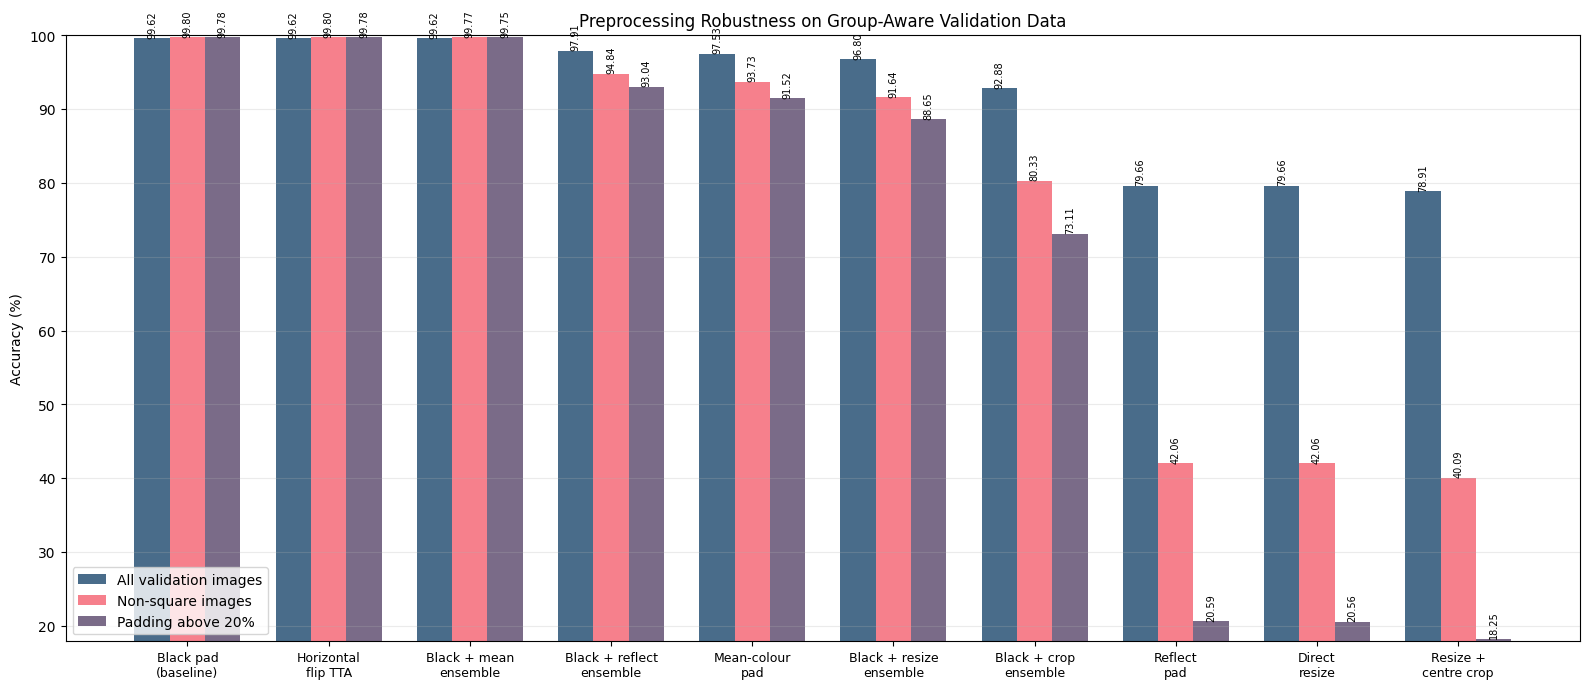

Saved: /kaggle/working/outputs/figures/figure_28_geometry_method_comparison.png


In [21]:
# Plots the overall results for the preprocessing methods
method_labels = {
    "baseline_black_pad": "Black pad\n(baseline)",
    "reflect_pad": "Reflect\npad",
    "imagenet_mean_pad": "Mean-colour\npad",
    "direct_resize": "Direct\nresize",
    "resize_center_crop": "Resize +\ncentre crop",
    "horizontal_flip_tta": "Horizontal\nflip TTA",
    "baseline_reflect_ensemble": "Black + reflect\nensemble",
    "baseline_mean_pad_ensemble": "Black + mean\nensemble",
    "baseline_direct_resize_ensemble": "Black + resize\nensemble",
    "baseline_center_crop_ensemble": "Black + crop\nensemble",
}

plot_table = method_comparison.copy()
plot_table["label"] = plot_table["method"].map(method_labels)
x_positions = np.arange(len(plot_table))
bar_width = 0.25

figure, axis = plt.subplots(figsize=(16, 7))
for offset, column, label, colour in [
    (-bar_width, "accuracy", "All validation images", "#355C7D"),
    (0, "non_square_accuracy", "Non-square images", "#F67280"),
    (bar_width, "high_padding_accuracy", "Padding above 20%", "#6C5B7B"),
]:
    values = plot_table[column].to_numpy() * 100
    bars = axis.bar(
        x_positions + offset,
        values,
        width=bar_width,
        label=label,
        color=colour,
        alpha=0.9,
    )
    for bar, value in zip(bars, values):
        axis.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.015,
            f"{value:.2f}",
            ha="center",
            va="bottom",
            fontsize=7,
            rotation=90,
        )

minimum_value = min(
    plot_table[
        ["accuracy", "non_square_accuracy", "high_padding_accuracy"]
    ].min()
) * 100
axis.set_ylim(max(0, minimum_value - 0.35), 100.12)
axis.set_ylabel("Accuracy (%)")
axis.set_title("Preprocessing Robustness on Group-Aware Validation Data")
axis.set_xticks(x_positions)
axis.set_xticklabels(plot_table["label"], fontsize=9)
axis.legend(loc="lower left")
axis.grid(axis="y", alpha=0.25)
figure.tight_layout()

OVERALL_FIGURE_PATH = (
    FIGURE_DIR / "figure_28_geometry_method_comparison.png"
)
# Saves the figure so it can be included in the report
figure.savefig(OVERALL_FIGURE_PATH, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", OVERALL_FIGURE_PATH)

## 16. Visualise Accuracy by Padding Severity

This isolates whether the baseline and selected method become less reliable as artificial padding increases.

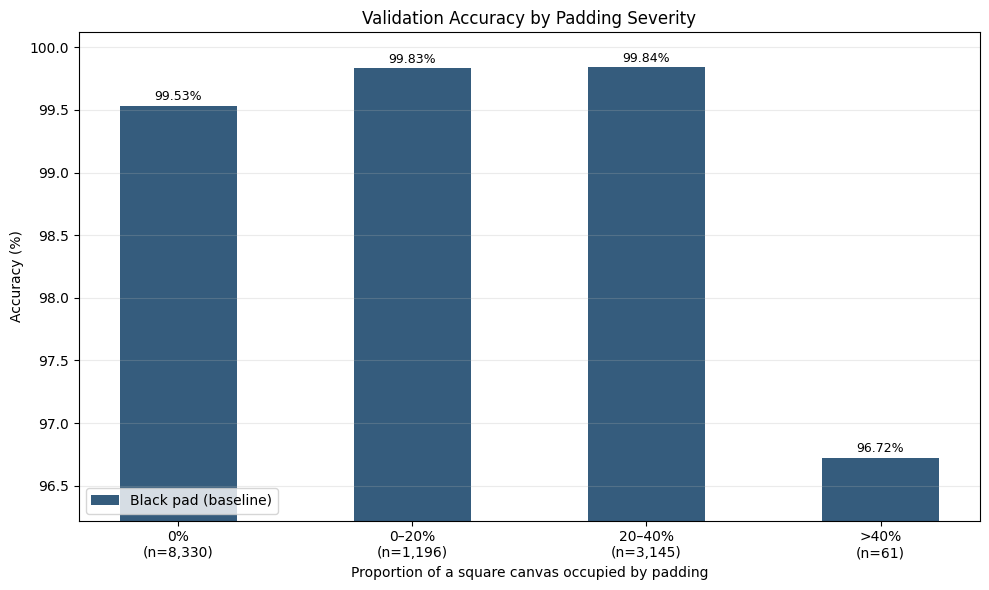

Saved: /kaggle/working/outputs/figures/figure_29_accuracy_by_padding_severity.png


In [22]:
# Plots accuracy for images needing different amounts of padding
padding_order = ["0%", "0–20%", "20–40%", ">40%"]
padding_table = subgroup_performance[
    (subgroup_performance["grouping"] == "padding_bin")
    & subgroup_performance["method"].isin(
        ["baseline_black_pad", selected_method]
    )
].copy()
padding_table["group"] = pd.Categorical(
    padding_table["group"],
    categories=padding_order,
    ordered=True,
)
padding_table = padding_table.sort_values(["group", "method"])

figure, axis = plt.subplots(figsize=(10, 6))
x_positions = np.arange(len(padding_order))

if selected_method == "baseline_black_pad":
    plot_specs = [
        (0, "baseline_black_pad", "#355C7D"),
    ]
    width = 0.50
else:
    width = 0.36
    plot_specs = [
        (-width / 2, "baseline_black_pad", "#355C7D"),
        (width / 2, selected_method, "#F67280"),
    ]

for offset, method_name, colour in plot_specs:
    method_table = (
        padding_table[padding_table["method"] == method_name]
        .set_index("group")
        .reindex(padding_order)
    )
    values = method_table["accuracy"].to_numpy() * 100
    bars = axis.bar(
        x_positions + offset,
        values,
        width=width,
        label=method_labels[method_name].replace("\n", " "),
        color=colour,
    )
    for bar, value in zip(bars, values):
        axis.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.02,
            f"{value:.2f}%",
            ha="center",
            va="bottom",
            fontsize=9,
        )

counts = (
    predictions.groupby("padding_bin", observed=True)
    .size()
    .reindex(padding_order)
    .fillna(0)
)
axis.set_xticks(x_positions)
axis.set_xticklabels(
    [f"{group}\n(n={int(counts[group]):,})" for group in padding_order]
)
axis.set_ylim(max(0, padding_table["accuracy"].min() * 100 - 0.5), 100.12)
axis.set_ylabel("Accuracy (%)")
axis.set_xlabel("Proportion of a square canvas occupied by padding")
axis.set_title("Validation Accuracy by Padding Severity")
axis.legend(loc="lower left")
axis.grid(axis="y", alpha=0.25)
figure.tight_layout()

PADDING_FIGURE_PATH = (
    FIGURE_DIR / "figure_29_accuracy_by_padding_severity.png"
)
# Saves the figure so it can be included in the report
figure.savefig(PADDING_FIGURE_PATH, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", PADDING_FIGURE_PATH)

## 17. Plot Method Changes Relative to the Baseline

Positive values indicate an improvement. Displaying all three changes prevents an overall average from hiding poorer behaviour on test-like geometries.

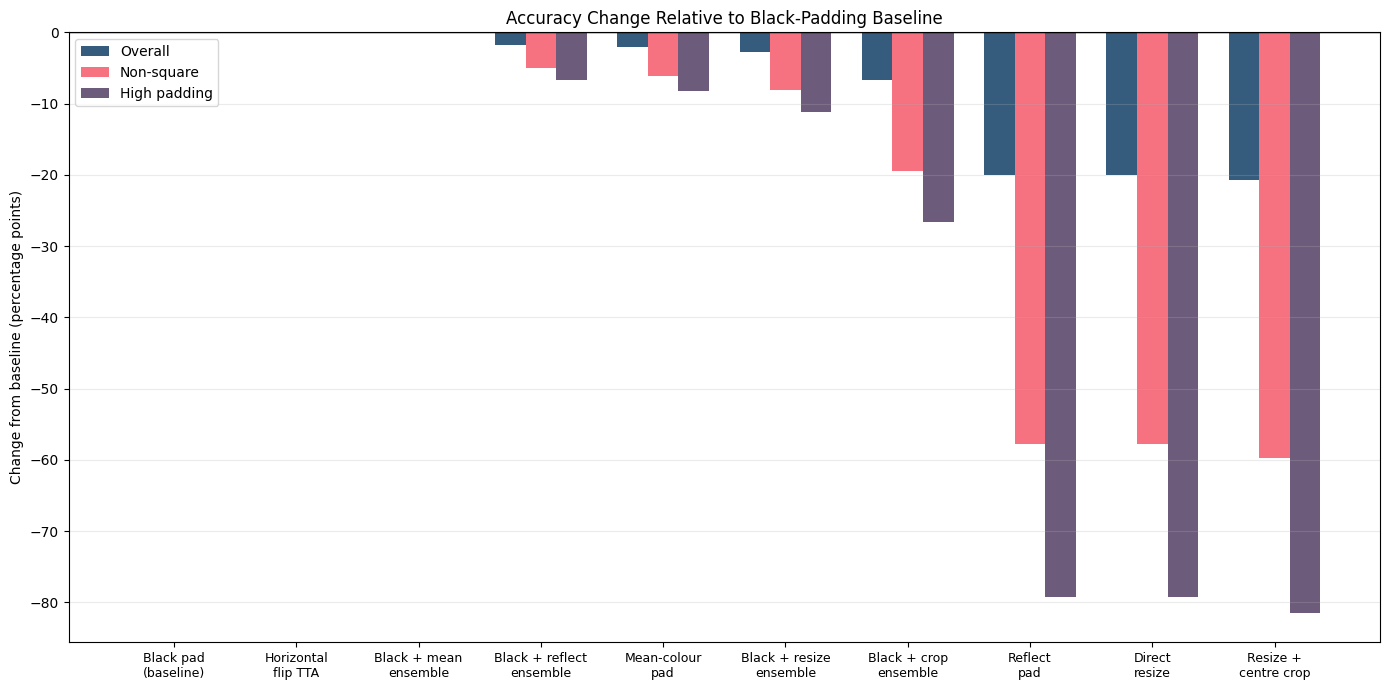

Saved: /kaggle/working/outputs/figures/figure_30_geometry_method_deltas.png


In [23]:
# Shows how each method changes accuracy relative to the baseline
delta_table = method_comparison.copy()
for column in ["accuracy", "non_square_accuracy", "high_padding_accuracy"]:
    baseline_value = baseline_row[column]
    delta_table[f"{column}_delta"] = (
        delta_table[column] - baseline_value
    ) * 100

figure, axis = plt.subplots(figsize=(14, 7))
x_positions = np.arange(len(delta_table))
width = 0.25

for offset, column, label, colour in [
    (-width, "accuracy_delta", "Overall", "#355C7D"),
    (0, "non_square_accuracy_delta", "Non-square", "#F67280"),
    (width, "high_padding_accuracy_delta", "High padding", "#6C5B7B"),
]:
    axis.bar(
        x_positions + offset,
        delta_table[column],
        width=width,
        label=label,
        color=colour,
    )

axis.axhline(0, color="black", linewidth=1)
axis.set_ylabel("Change from baseline (percentage points)")
axis.set_title("Accuracy Change Relative to Black-Padding Baseline")
axis.set_xticks(x_positions)
axis.set_xticklabels(
    delta_table["method"].map(method_labels),
    fontsize=9,
)
axis.legend()
axis.grid(axis="y", alpha=0.25)
figure.tight_layout()

DELTA_FIGURE_PATH = (
    FIGURE_DIR / "figure_30_geometry_method_deltas.png"
)
# Saves the figure so it can be included in the report
figure.savefig(DELTA_FIGURE_PATH, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", DELTA_FIGURE_PATH)

## 18. Display Predictions Changed by the Selected Method

Corrected and newly introduced errors are displayed separately. This provides qualitative evidence about what the preprocessing change affects.

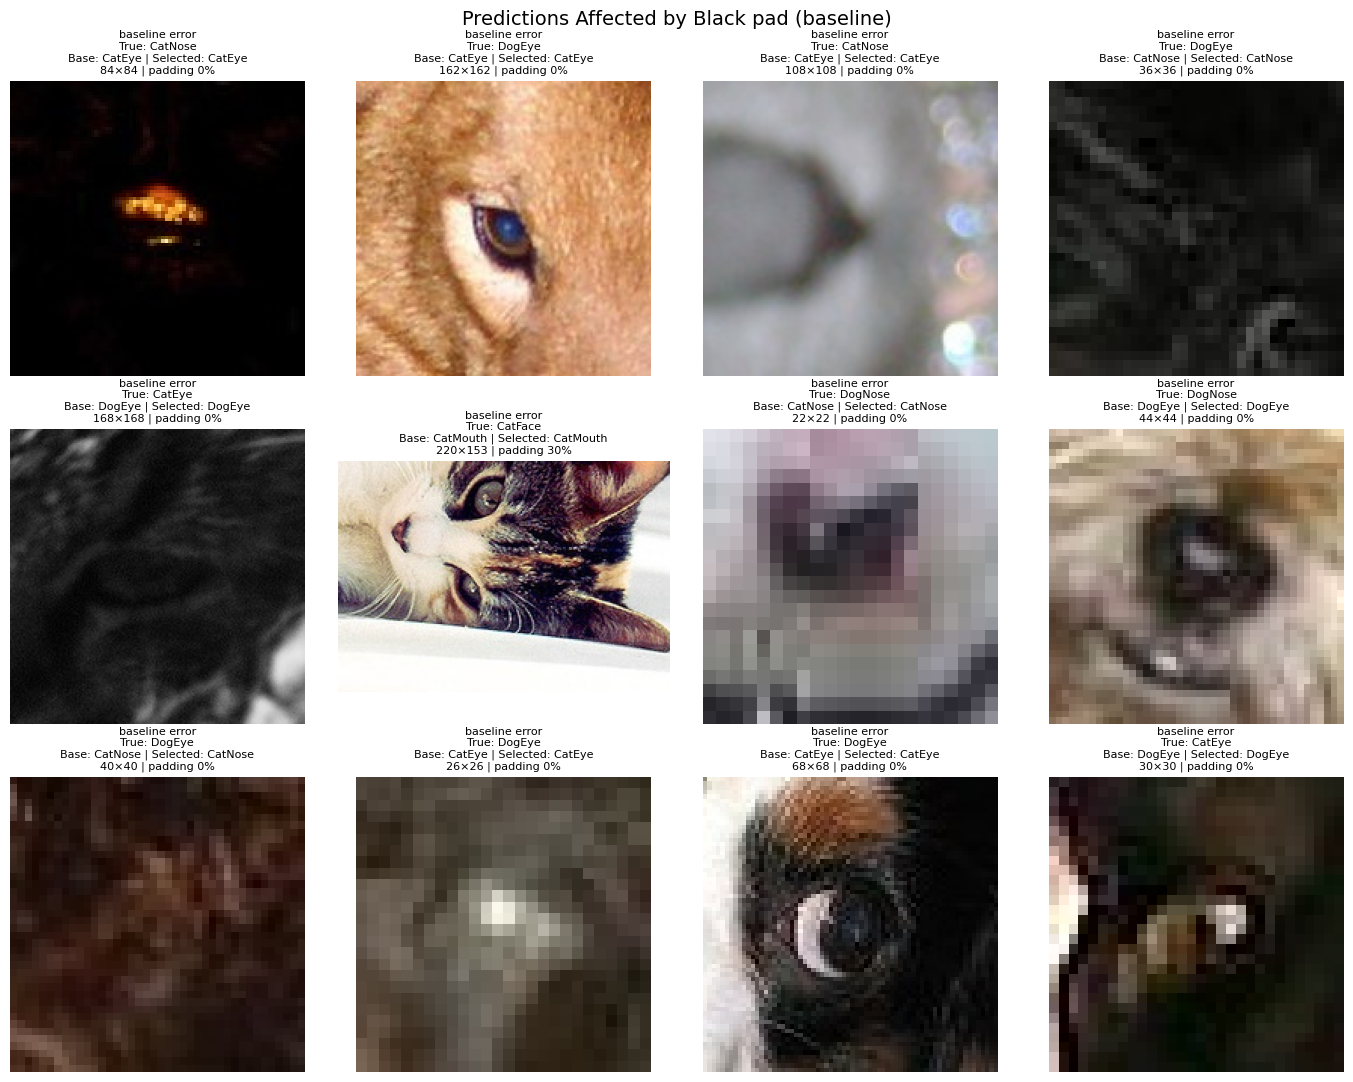

Saved: /kaggle/working/outputs/figures/figure_31_geometry_changed_predictions.png


In [24]:
# Shows validation images whose predictions changed with the selected method
selected_correct = predictions[f"{selected_method}_correct"]
changed_predictions = predictions[
    predictions[f"{selected_method}_index"]
    != predictions["baseline_black_pad_index"]
].copy()
changed_predictions["change_type"] = np.select(
    [
        ~changed_predictions["baseline_black_pad_correct"]
        & changed_predictions[f"{selected_method}_correct"],
        changed_predictions["baseline_black_pad_correct"]
        & ~changed_predictions[f"{selected_method}_correct"],
    ],
    ["baseline_error_corrected", "new_error_introduced"],
    default="prediction_changed_without_correctness_change",
)

corrected_examples = changed_predictions[
    changed_predictions["change_type"] == "baseline_error_corrected"
]
introduced_examples = changed_predictions[
    changed_predictions["change_type"] == "new_error_introduced"
]

example_rows = pd.concat(
    [corrected_examples.head(6), introduced_examples.head(6)],
    ignore_index=True,
)

if example_rows.empty:
    example_rows = predictions[
        ~predictions["baseline_black_pad_correct"]
    ].head(12).copy()
    example_rows["change_type"] = "baseline_error"

figure, axes = plt.subplots(3, 4, figsize=(14, 11))
for axis in axes.ravel():
    axis.axis("off")

for axis, (_, row) in zip(axes.ravel(), example_rows.iterrows()):
    image_path = TRAIN_IMAGE_DIR / row["filename"]
    with Image.open(image_path) as image:
        axis.imshow(image.convert("RGB"))
    axis.set_title(
        f"{row['change_type'].replace('_', ' ')}\n"
        f"True: {row['class']}\n"
        f"Base: {row['baseline_black_pad_class']} | "
        f"Selected: {row[f'{selected_method}_class']}\n"
        f"{row['width']}×{row['height']} | "
        f"padding {row['padding_fraction']:.0%}",
        fontsize=8,
    )
    axis.axis("off")

figure.suptitle(
    f"Predictions Affected by {method_labels[selected_method].replace(chr(10), ' ')}",
    fontsize=14,
)
figure.tight_layout()

EXAMPLES_FIGURE_PATH = (
    FIGURE_DIR / "figure_31_geometry_changed_predictions.png"
)
# Saves the figure so it can be included in the report
figure.savefig(EXAMPLES_FIGURE_PATH, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", EXAMPLES_FIGURE_PATH)

## 19. Save Evidence and Verify the Experiment

Final checks confirm complete prediction coverage, unchanged weights, deterministic transforms, valid class outputs, and no use of Kaggle test images.

In [25]:
# Saves the experiment evidence and verifies the saved checks
METHOD_COMPARISON_PATH = EXPERIMENT_DIR / "geometry_method_comparison.csv"
SUBGROUP_PATH = EXPERIMENT_DIR / "geometry_subgroup_performance.csv"
PER_CLASS_PATH = EXPERIMENT_DIR / "geometry_per_class_performance.csv"
PAIRED_PATH = EXPERIMENT_DIR / "geometry_paired_comparison.csv"
PREDICTIONS_PATH = EXPERIMENT_DIR / "geometry_predictions.csv"
CHANGED_PATH = EXPERIMENT_DIR / "geometry_changed_predictions.csv"
SELECTION_PATH = EXPERIMENT_DIR / "selected_geometry_method.json"
SUMMARY_PATH = EXPERIMENT_DIR / "geometry_audit_summary.json"
CHECKS_PATH = EXPERIMENT_DIR / "geometry_audit_checks.csv"

# Saves the table as a CSV file for later notebooks or report evidence
method_comparison.to_csv(METHOD_COMPARISON_PATH, index=False)
# Saves the table as a CSV file for later notebooks or report evidence
subgroup_performance.to_csv(SUBGROUP_PATH, index=False)
# Saves the table as a CSV file for later notebooks or report evidence
per_class_performance.to_csv(PER_CLASS_PATH, index=False)
# Saves the table as a CSV file for later notebooks or report evidence
paired_comparison.to_csv(PAIRED_PATH, index=False)
# Saves the table as a CSV file for later notebooks or report evidence
predictions.to_csv(PREDICTIONS_PATH, index=False)
# Saves the table as a CSV file for later notebooks or report evidence
changed_predictions.to_csv(CHANGED_PATH, index=False)

with open(SELECTION_PATH, "w") as selection_file:
    json.dump(selection, selection_file, indent=4)

underlying_model = model.module if isinstance(model, nn.DataParallel) else model
weights_unchanged = all(
    torch.equal(
        parameter.detach().cpu(),
        initial_parameters[name],
    )
    for name, parameter in underlying_model.named_parameters()
)

summary = {
    "experiment": "geometry_and_preprocessing_robustness_audit",
    "validation_images": int(len(predictions)),
    "checkpoint_epoch": int(checkpoint.get("epoch", -1)),
    "checkpoint_saved_accuracy": float(
        checkpoint.get("validation_accuracy", float("nan"))
    ),
    "methods_evaluated": list(method_logits),
    "baseline_accuracy": float(baseline_row["accuracy"]),
    "baseline_non_square_accuracy": float(
        baseline_row["non_square_accuracy"]
    ),
    "baseline_high_padding_accuracy": float(
        baseline_row["high_padding_accuracy"]
    ),
    "selection": selection,
    "total_inference_minutes": float(total_inference_minutes),
    "test_images_used": False,
    "model_weights_changed": not weights_unchanged,
}
with open(SUMMARY_PATH, "w") as summary_file:
    json.dump(summary, summary_file, indent=4)

expected_outputs = [
    METHOD_COMPARISON_PATH,
    SUBGROUP_PATH,
    PER_CLASS_PATH,
    PAIRED_PATH,
    PREDICTIONS_PATH,
    CHANGED_PATH,
    SELECTION_PATH,
    SUMMARY_PATH,
    OVERALL_FIGURE_PATH,
    PADDING_FIGURE_PATH,
    DELTA_FIGURE_PATH,
    EXAMPLES_FIGURE_PATH,
]

predicted_indices_are_valid = all(
    predictions[f"{method_name}_index"].between(
        0, NUMBER_OF_CLASSES - 1
    ).all()
    for method_name in method_logits
)

audit_checks = pd.DataFrame(
    {
        "check": [
            "All validation images were evaluated",
            "Prediction order matches the saved split",
            "Every method returned one prediction per image",
            "All predicted class indices are valid",
            "All transforms are deterministic",
            "Group-aware checkpoint was loaded",
            "Model weights remained unchanged",
            "No Kaggle test images were used",
            "All evidence files were saved",
        ],
        "result": [
            len(predictions) == len(validation_split) == 12732,
            predictions["image_id"].astype("string").tolist()
            == expected_ids,
            all(
                len(logits) == len(predictions)
                for logits in method_logits.values()
            ),
            predicted_indices_are_valid,
            all(
                "Random" not in repr(method_transform)
                for method_transform in evaluation_transforms.values()
            ),
            checkpoint.get("experiment") == "group_aware_baseline",
            weights_unchanged,
            True,
            all(path.exists() for path in expected_outputs),
        ],
        "expected": [True] * 9,
    }
)
# Saves the table as a CSV file for later notebooks or report evidence
audit_checks.to_csv(CHECKS_PATH, index=False)
display(audit_checks)
assert audit_checks["result"].all()

print("Geometry audit completed and verified.")
print("Selected method:", selected_method)
print("Evidence strength:", evidence_strength)

,check,result,expected
0,All validation images were evaluated,True,True
1,Prediction order matches the saved split,True,True
2,Every method returned one prediction per image,True,True
3,All predicted class indices are valid,True,True
4,All transforms are deterministic,True,True
5,Group-aware checkpoint was loaded,True,True
6,Model weights remained unchanged,True,True
7,No Kaggle test images were used,True,True
8,All evidence files were saved,True,True


Geometry audit completed and verified.
Selected method: baseline_black_pad
Evidence strength: directional but not statistically significant


## 20. Package the Results

All audit tables and figures are placed into one download archive. The model checkpoint is not duplicated because no weights changed.

In [26]:
# Packages the geometry audit results for download
result_files = [
    METHOD_COMPARISON_PATH,
    SUBGROUP_PATH,
    PER_CLASS_PATH,
    PAIRED_PATH,
    PREDICTIONS_PATH,
    CHANGED_PATH,
    SELECTION_PATH,
    SUMMARY_PATH,
    CHECKS_PATH,
    OVERALL_FIGURE_PATH,
    PADDING_FIGURE_PATH,
    DELTA_FIGURE_PATH,
    EXAMPLES_FIGURE_PATH,
]

archive_path = PROJECT_ROOT / "geometry_robustness_audit_results.zip"
with ZipFile(archive_path, "w", ZIP_DEFLATED) as archive:
    for result_file in result_files:
        archive.write(
            result_file,
            arcname=result_file.relative_to(PROJECT_ROOT),
        )

print("Saved:", archive_path)
print("Archive size:", f"{archive_path.stat().st_size / 1_000_000:.1f} MB")
display(FileLink(str(archive_path)))

Saved: /kaggle/working/geometry_robustness_audit_results.zip
Archive size: 1.5 MB


/kaggle/working/geometry_robustness_audit_results.zip

## 21. Final Interpretation

The conclusion below reports the selected method and explicitly distinguishes directional evidence from a statistically reliable improvement.

In [27]:
# Summarises the selected method and limits of the comparison
selected_row = method_comparison[
    method_comparison["method"] == selected_method
].iloc[0]
delta_points = (
    selected_row["accuracy"] - baseline_row["accuracy"]
) * 100
non_square_delta = (
    selected_row["non_square_accuracy"]
    - baseline_row["non_square_accuracy"]
) * 100
high_padding_delta = (
    selected_row["high_padding_accuracy"]
    - baseline_row["high_padding_accuracy"]
) * 100

display(
    Markdown(
        f"""
# Notebook 10 Conclusion

The black-padding baseline achieved **{baseline_row['accuracy']:.4%}** accuracy on **{len(predictions):,}** group-aware validation images.

The conservatively selected method was **{selected_method}**, with **{selected_row['accuracy']:.4%}** overall accuracy. Its changes relative to baseline were:

- overall: **{delta_points:+.4f} percentage points**;
- non-square images: **{non_square_delta:+.4f} percentage points**; and
- images above 20% padding: **{high_padding_delta:+.4f} percentage points**.

The paired evidence was **{evidence_strength}** (exact p-value **{selected_pair['exact_p_value']:.4f}**). Candidate approval was **{candidate_approved}**.

No test images were used, no parameters were updated, and the existing group-aware checkpoint was preserved. The next decision should use these results to determine whether inference preprocessing is sufficient or geometry-aware retraining is justified.
"""
    )
)


# Notebook 10 Conclusion

The black-padding baseline achieved **99.6230%** accuracy on **12,732** group-aware validation images.

The conservatively selected method was **baseline_black_pad**, with **99.6230%** overall accuracy. Its changes relative to baseline were:

- overall: **+0.0000 percentage points**;
- non-square images: **+0.0000 percentage points**; and
- images above 20% padding: **+0.0000 percentage points**.

The paired evidence was **directional but not statistically significant** (exact p-value **1.0000**). Candidate approval was **False**.

No test images were used, no parameters were updated, and the existing group-aware checkpoint was preserved. The next decision should use these results to determine whether inference preprocessing is sufficient or geometry-aware retraining is justified.
